# **Lab 6 - Frequency Domain (Solution)**

**Student ID:** 2240002024

**Assessment Task:** Using the same Cameraman image, apply the Sobel filter(s) in the frequency domain and show the results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, io
from skimage.transform import resize
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from scipy.ndimage import convolve

## **Task 1 (Lab): Laplacian Filter in the Frequency Domain**

This is the code from the manual, run first to make sure everything works.

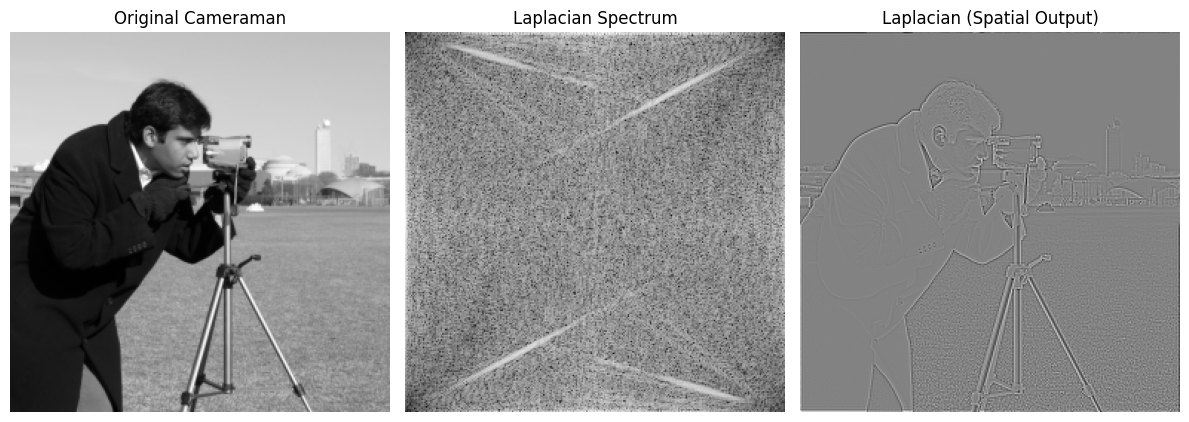

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT

# Save the image used in this lab
io.imsave('images/cameraman.png', (image * 255).astype(np.uint8))

# Get image size
M, N = image.shape

# Generate frequency grid
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Laplacian filter in the frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# FFT -> multiply -> inverse FFT
F = np.fft.fft2(image)
F_lap = F * laplacian_filter
laplacian_image = np.fft.ifft2(F_lap).real

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1), plt.imshow(image, cmap='gray'), plt.title('Original Cameraman'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray'), plt.title('Laplacian Spectrum'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(laplacian_image, cmap='gray'), plt.title('Laplacian (Spatial Output)'), plt.axis('off')
plt.tight_layout()
plt.savefig('results/task1_laplacian.png', dpi=110, bbox_inches='tight')
plt.show()

## **Assessment Task: Sobel Filters in the Frequency Domain**

### Step 1: Define the Sobel kernels and embed them in an image-sized array

In [3]:
# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain (provided function)
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# FFT of the image
F = fft2(image)

# FFT of the centered Sobel filters (same size as the image)
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

print('Image FFT shape :', F.shape)
print('Filter FFT shape:', H_x.shape)

Image FFT shape : (256, 256)
Filter FFT shape: (256, 256)


### Step 2: Show the frequency response of the filters

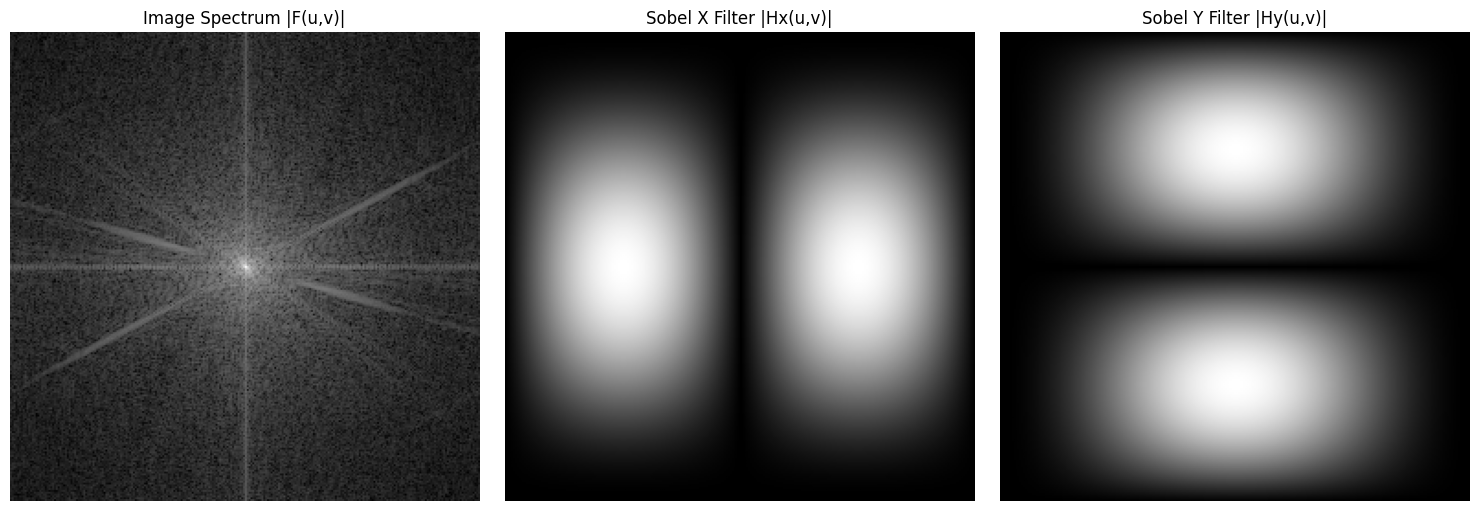

In [4]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(np.log(1 + np.abs(fftshift(F))), cmap='gray'), plt.title('Image Spectrum |F(u,v)|'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(np.abs(fftshift(H_x)), cmap='gray'), plt.title('Sobel X Filter |Hx(u,v)|'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(np.abs(fftshift(H_y)), cmap='gray'), plt.title('Sobel Y Filter |Hy(u,v)|'), plt.axis('off')
plt.tight_layout()
plt.savefig('results/sobel_spectra.png', dpi=110, bbox_inches='tight')
plt.show()

### Step 3: Multiply in the frequency domain and go back with the inverse FFT

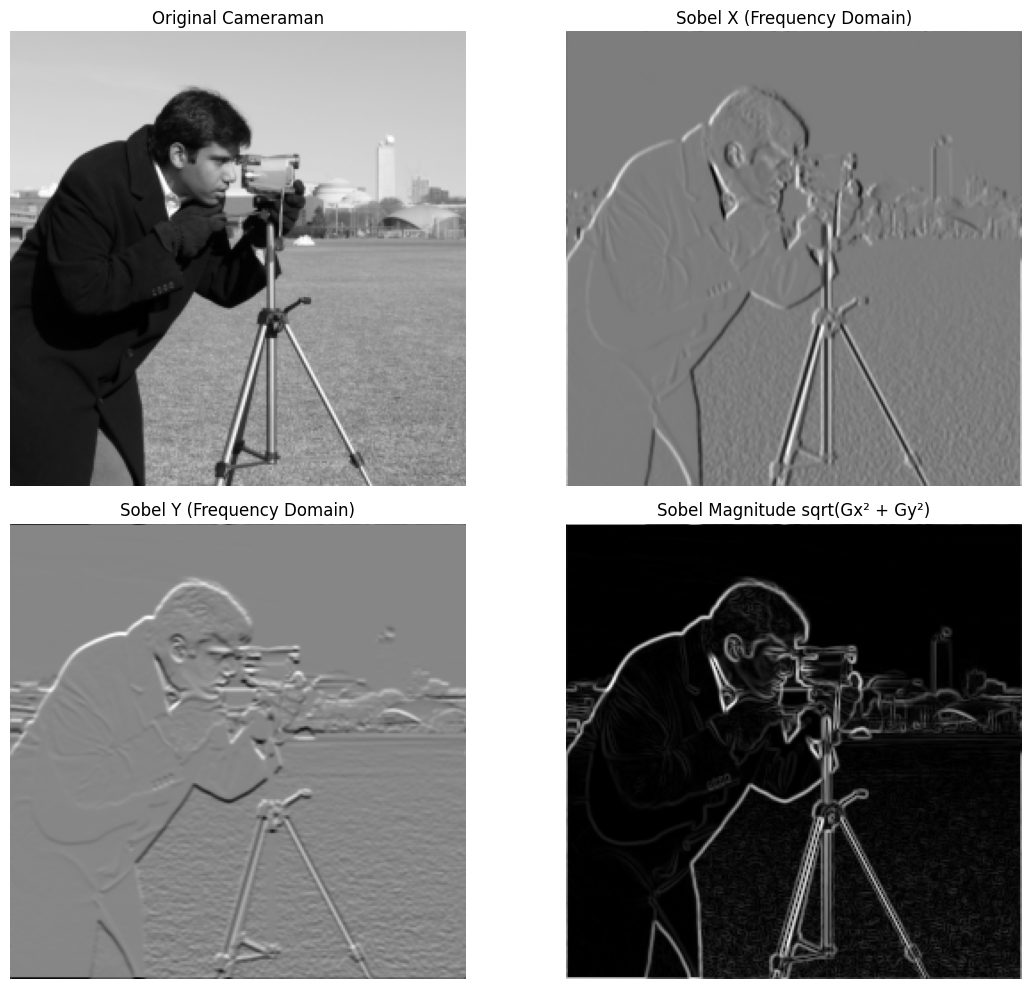

In [5]:
# Multiply in the frequency domain
G_x = F * H_x
G_y = F * H_y

# Inverse FFT to get the spatial result
sobel_x_img = np.real(ifft2(G_x))
sobel_y_img = np.real(ifft2(G_y))

# Gradient magnitude
sobel_mag = np.sqrt(sobel_x_img**2 + sobel_y_img**2)

plt.figure(figsize=(12, 10))
plt.subplot(2, 2, 1), plt.imshow(image, cmap='gray'), plt.title('Original Cameraman'), plt.axis('off')
plt.subplot(2, 2, 2), plt.imshow(sobel_x_img, cmap='gray'), plt.title('Sobel X (Frequency Domain)'), plt.axis('off')
plt.subplot(2, 2, 3), plt.imshow(sobel_y_img, cmap='gray'), plt.title('Sobel Y (Frequency Domain)'), plt.axis('off')
plt.subplot(2, 2, 4), plt.imshow(sobel_mag, cmap='gray'), plt.title('Sobel Magnitude sqrt(Gx² + Gy²)'), plt.axis('off')
plt.tight_layout()
plt.savefig('results/sobel_frequency_results.png', dpi=110, bbox_inches='tight')
plt.show()

### Step 4: Check the result against Sobel in the spatial domain

Multiplying in the frequency domain is the same as (circular) convolution in the spatial domain, so the result should be the same as convolving the image directly with the Sobel kernels.

Max difference (Sobel X)   : 1.7763568394002505e-15
Max difference (Sobel Y)   : 2.9559688030644793e-15
Max difference (Magnitude) : 2.851885394505871e-15


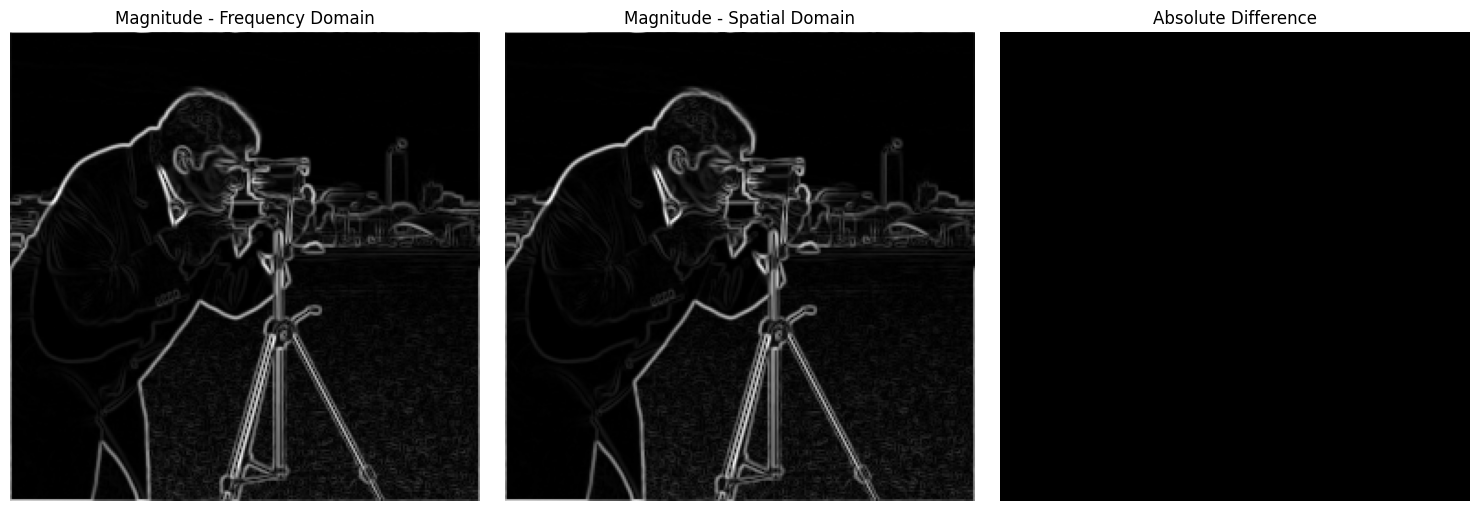

In [6]:
# Spatial-domain convolution (mode='wrap' = circular, same as the FFT)
spatial_x = convolve(image, sobel_x, mode='wrap')
spatial_y = convolve(image, sobel_y, mode='wrap')
spatial_mag = np.sqrt(spatial_x**2 + spatial_y**2)

print('Max difference (Sobel X)   :', np.max(np.abs(sobel_x_img - spatial_x)))
print('Max difference (Sobel Y)   :', np.max(np.abs(sobel_y_img - spatial_y)))
print('Max difference (Magnitude) :', np.max(np.abs(sobel_mag - spatial_mag)))

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1), plt.imshow(sobel_mag, cmap='gray'), plt.title('Magnitude - Frequency Domain'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(spatial_mag, cmap='gray'), plt.title('Magnitude - Spatial Domain'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(np.abs(sobel_mag - spatial_mag), cmap='gray', vmin=0, vmax=1), plt.title('Absolute Difference'), plt.axis('off')
plt.tight_layout()
plt.savefig('results/sobel_comparison.png', dpi=110, bbox_inches='tight')
plt.show()

### Discussion

- **How it works:** by the convolution theorem, convolution in the spatial domain equals multiplication in the frequency domain: `f * h  <=>  F(u,v) · H(u,v)`. Each 3x3 Sobel kernel was zero-padded to 256x256, centred, and moved to (0,0) with `ifftshift`, so `fft2` gives its frequency response H. Then `ifft2(F · H)` gives the filtered image.
- **Frequency response:** |Hx| is zero on the centre column (no horizontal change, including the DC term) and small at the left/right edges, so it passes the middle horizontal frequencies, which means it detects **vertical edges**. Along the vertical direction it gets smaller away from the centre, which is the `[1 2 1]` smoothing part of Sobel (low-pass). |Hy| is the same pattern rotated by 90°, so it detects **horizontal edges**.
- **Results:** Sobel X shows the tripod legs, the coat outline and the buildings (vertical edges). Sobel Y shows the horizon, the top of the camera and the shoulders (horizontal edges). Flat areas like the sky become grey (value ≈ 0). The magnitude combines both directions and gives a complete edge map.
- **Check:** the maximum difference between the frequency-domain result and spatial convolution is about 3 × 10⁻¹⁵, which is only rounding error, so both methods give the same result.
- **Border lines:** thin lines appear at the image borders because the FFT assumes the image repeats periodically, so the left edge is treated as a neighbour of the right edge (wrap-around). Zero-padding the image before the FFT would remove this.